# Analyse Big Data des accidents routiers d'Australie-Méridionale avec PySpark

**Reproduction de l'article de Rakesh Nain** : *« Big data Analysis of Road Crash Data using PySpark with PySpark Tutorial »* (Medium, 2 janvier 2021).

Le but est de refaire la même étude avec les trois structures de données de Spark : **RDD**, **DataFrame** et **Spark SQL**, sur les mêmes données (accidents de la route en Australie-Méridionale, 2012-2019).

**Données** : *Road Crash Data* du Department of Planning, Transport and Infrastructure (DPTI), publiées sur https://data.sa.gov.au. Deux tables sont utilisées :
- `crash_data` : un enregistrement par accident (lieu, heure, gravité, conditions, nombre de victimes…) ;
- `units_data` : un enregistrement par véhicule/unité impliqué (type, année du véhicule, sexe et âge du conducteur, permis…).

Elles sont reliées par `REPORT_ID`. Les fichiers sont ceux du dépôt GitHub de l'auteur, qui a déjà trié les CSV dans les bons dossiers.

**Ce que ce notebook fait de plus que l'article**
1. Chaque résultat publié dans l'article est recalculé et **comparé** (cellule de vérification à la fin).
2. Les trois méthodes (RDD, DataFrame, SQL) sont comparées entre elles et **doivent donner le même résultat**.
3. Deux problèmes de l'article sont mesurés et corrigés (virgules dans les champs CSV, et `COUNT` au lieu de `SUM`), voir la section 4.

> Le jour exact d'un accident n'est pas publié (donnée sensible). La colonne `Day` contient donc le **jour de la semaine**, et une « date » s'écrit *Année-Mois-JourDeLaSemaine*, par exemple `2017-January-Sunday`.

## 0. Préparation de l'environnement

In [1]:
import os, sys, shutil, subprocess

# PySpark (installé automatiquement si absent, utile sur Google Colab)
try:
    import pyspark
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "pyspark==3.5.3"])
    import pyspark

# Données : on récupère les dossiers crash_data/ et units_data/ du dépôt GitHub de l'auteur
REPO = "https://github.com/RakeshNain/Big-data-Analysis-of-Road-Crash-Data-using-PySpark-with-PySpark-Tutorial.git"
if not (os.path.isdir("crash_data") and os.path.isdir("units_data")):
    subprocess.check_call(["git", "clone", "--depth", "1", "-q", REPO, "_repo_tmp"])
    for d in ("crash_data", "units_data"):
        shutil.copytree(os.path.join("_repo_tmp", d), d)
    shutil.rmtree("_repo_tmp")

print("PySpark", pyspark.__version__)
print("crash_data :", sorted(os.listdir("crash_data")))
print("units_data :", sorted(os.listdir("units_data")))

PySpark 4.0.4
crash_data : ['2012_DATA_SA_Crash.csv', '2013_DATA_SA_Crash.csv', '2014_DATA_SA_Crash.csv', '2015_DATA_SA_Crash.csv', '2016_DATA_SA_Crash.csv', '2017_DATA_SA_Crash.csv', '2018_DATA_SA_Crash.csv', '2019_DATA_SA_Crash.csv']
units_data : ['2012_DATA_SA_Units.csv', '2013_DATA_SA_Units.csv', '2014_DATA_SA_Units.csv', '2015_DATA_SA_Units.csv', '2016_DATA_SA_Units.csv', '2017_DATA_SA_Units.csv', '2018_DATA_SA_Units.csv', '2019_DATA_SA_Units.csv']


In [2]:
import csv
import pandas as pd
import matplotlib.pyplot as plt

from pyspark import SparkConf, SparkContext
from pyspark.rdd import RDD
from pyspark.sql import SparkSession
import pyspark.sql.functions as F
from pyspark.sql.functions import col, udf
from pyspark.sql.types import IntegerType, StringType, FloatType

**Calcul parallèle ou distribué ?** Ici, tout tourne sur **une seule machine** : c'est du calcul *parallèle* (le travail est réparti entre les cœurs). Le calcul *distribué* répartit le travail entre plusieurs machines. Le code PySpark est presque identique dans les deux cas, seule la configuration du maître (`master`) change.

In [3]:
# local[*] : Spark utilise autant de threads que de cœurs logiques. local[k] : k threads.
master = "local[*]"
app_name = "Big data Analysis of Road Crash Data"

spark_conf = (SparkConf().setMaster(master).setAppName(app_name)
              # Les jointures/agrégations créent 200 partitions par défaut : c'est beaucoup trop
              # pour ~130 000 lignes, on en prend 8.
              .set("spark.sql.shuffle.partitions", "8")
              .set("spark.ui.showConsoleProgress", "false"))

spark = SparkSession.builder.config(conf=spark_conf).getOrCreate()
sc = spark.sparkContext
sc.setLogLevel("ERROR")
print("Cœurs utilisés (parallélisme par défaut) :", sc.defaultParallelism)

Cœurs utilisés (parallélisme par défaut) : 2


## 1. Analyse avec les RDD

Un **RDD** (*Resilient Distributed Dataset*) est une collection **immuable** d'objets, découpée en **partitions** qui peuvent être traitées en parallèle. On travaille avec des *transformations* (`map`, `filter`, `join`… qui sont paresseuses) et des *actions* (`count`, `collect`, `take`… qui déclenchent le calcul).

Un RDD se crée de deux façons : `parallelize()` (depuis une collection Python) ou `textFile()` (depuis des fichiers texte).

In [4]:
# parallelize() : par défaut, une partition par thread
data_list = list(range(10))
rdd = sc.parallelize(data_list)
print("Partitions par défaut :", rdd.getNumPartitions())

# on peut imposer le nombre de partitions
rdd = sc.parallelize(data_list, 5)
print("Partitions choisies   :", rdd.getNumPartitions())
print("Contenu de chaque partition :", rdd.glom().collect())

Partitions par défaut : 2
Partitions choisies   : 5
Contenu de chaque partition : [[0, 1], [2, 3], [4, 5], [6, 7], [8, 9]]


`textFile()` lit des fichiers texte : **chaque ligne devient un élément** du RDD. On charge tous les CSV d'un coup avec un joker `*`.

In [5]:
units_rdd = sc.textFile("./units_data/*.csv")
crash_rdd = sc.textFile("./crash_data/*.csv")

# Chaque CSV commence par une ligne d'en-tête : on la repère puis on la retire (elle est identique dans les 8 fichiers)
units_header = units_rdd.first()
crash_header = crash_rdd.first()
units_rdd = units_rdd.filter(lambda row: row != units_header).cache()
crash_rdd = crash_rdd.filter(lambda row: row != crash_header).cache()

print("Nombre de lignes units_rdd :", units_rdd.count())
print("Nombre de lignes crash_rdd :", crash_rdd.count())
print("\nExemple (units) :", units_rdd.take(2))

Nombre de lignes units_rdd : 272591
Nombre de lignes crash_rdd : 127672

Exemple (units) : ['"2012-1-21/08/2019","01",0,,"Pedal Cycle",,"South West","Male","035",,,,,"Straight Ahead","001","5074",,', '"2012-1-21/08/2019","02",0,"SA","Motor Cars - Sedan","2009","North West","Female","050","SA","C ","Full","Unknown","Leaving Private Driveway","001","5089",,']


Sans consigne, Spark répartit les fichiers de façon équilibrée. Ici on regarde le nombre de partitions obtenu :

In [6]:
print("Units :", units_rdd.getNumPartitions(), "partitions")
print("Crash :", crash_rdd.getNumPartitions(), "partitions")

Units : 8 partitions
Crash : 8 partitions


Le nombre de partitions dépend de la machine et de la taille des fichiers (l'article en obtient 8 sur sa machine ; cela peut varier chez vous, ce n'est pas un résultat de l'analyse).

### Partitionnement personnalisé

On peut choisir soi-même la partition de chaque enregistrement. Exemple : une partition pour les véhicules **immatriculés en Australie-Méridionale (SA)** et une pour tous les autres. Il faut pour cela un RDD *clé-valeur* dont la clé est l'état d'immatriculation (colonne `Veh Reg State`, 4ᵉ colonne).

In [7]:
def parseRecord(line):
    fields = [v.replace('"', '') for v in line.split(',')]
    return (fields[3], [x for i, x in enumerate(fields) if i != 3])   # (état d'immatriculation, autres colonnes)

units_state_rdd = units_rdd.map(parseRecord)

def hash_SA(key):
    return 0 if key == 'SA' else 1

SA_partitioned_rdd = units_state_rdd.partitionBy(2, hash_SA)

def print_partitions(data):
    "Affiche le nombre d'enregistrements par partition."
    rdd_ = data if isinstance(data, RDD) else data.rdd
    sizes = rdd_.glom().map(len).collect()
    print("NOMBRE DE PARTITIONS :", len(sizes))
    for i, n in enumerate(sizes):
        print(f"Partition {i} : {n} enregistrements")

print_partitions(SA_partitioned_rdd)

NOMBRE DE PARTITIONS : 2
Partition 0 : 218366 enregistrements
Partition 1 : 54225 enregistrements


### Un piège : les virgules à l'intérieur des champs CSV

L'article découpe chaque ligne avec `line.split(',')`. C'est correct pour le fichier *units*, mais **pas pour le fichier *crash*** : certains champs entre guillemets contiennent eux-mêmes des virgules (par exemple `"CC OF NORWOOD,PAYNEHAM & ST PETERS"` dans `LGA Name`). Le découpage naïf produit alors plus de 33 colonnes et **décale** toutes les colonnes suivantes.

Mesurons-le, puis utilisons le module `csv` (qui gère les guillemets) pour toutes les analyses RDD qui suivent.

In [8]:
def parse_naive(line):
    return [v.replace('"', '') for v in line.split(',')]

def parse_csv(line):
    return next(csv.reader([line]))          # respecte les guillemets

n_units_bad = units_rdd.filter(lambda l: len(parse_naive(l)) != 18).count()
n_crash_naive_bad = crash_rdd.filter(lambda l: len(parse_naive(l)) != 33).count()
n_crash_csv_bad = crash_rdd.filter(lambda l: len(parse_csv(l)) != 33).count()

print(f"units : lignes mal découpées avec split(',') : {n_units_bad}")
print(f"crash : lignes mal découpées avec split(',') : {n_crash_naive_bad} sur {crash_rdd.count()}")
print(f"crash : lignes mal découpées avec le module csv : {n_crash_csv_bad}")

# Index des colonnes par nom, pour ne plus écrire de numéros « magiques »
u_cols = parse_csv(units_header)
c_cols = parse_csv(crash_header)
ui = {name: i for i, name in enumerate(u_cols)}
ci = {name: i for i, name in enumerate(c_cols)}

units : lignes mal découpées avec split(',') : 0
crash : lignes mal découpées avec split(',') : 21379 sur 127672
crash : lignes mal découpées avec le module csv : 0


### Requête RDD 1 : âge moyen des conducteurs, hommes et femmes

In [9]:
def parseGenderAge(line):
    f = parse_csv(line)
    sex, age = f[ui['Sex']], f[ui['Age']]
    if age != 'XXX' and age != '' and sex != 'Unknown':
        return (sex, int(age))

gender_age_rdd = units_rdd.map(parseGenderAge).filter(lambda x: x is not None)

# Version de l'article : groupByKey (regroupe toutes les valeurs d'un sexe en mémoire)
avg_groupby = dict(gender_age_rdd.groupByKey().mapValues(lambda x: round(sum(x) / len(x), 2)).collect())

# Meilleure pratique : (somme, effectif) combinés partition par partition avec reduceByKey
avg_reduce = dict(gender_age_rdd.mapValues(lambda a: (a, 1))
                  .reduceByKey(lambda x, y: (x[0] + y[0], x[1] + y[1]))
                  .mapValues(lambda s: round(s[0] / s[1], 2)).collect())

print("groupByKey :", avg_groupby)
print("reduceByKey :", avg_reduce)

groupByKey : {'Male': 40.8, 'Female': 40.08}
reduceByKey : {'Male': 40.8, 'Female': 40.08}


L'âge moyen des hommes et des femmes impliqués dans un accident est quasiment le même (environ 40 ans). `reduceByKey` donne le même résultat que `groupByKey` mais sans rassembler toutes les valeurs : c'est la méthode à privilégier sur de gros volumes.

### Requête RDD 2 : véhicules les plus anciens et les plus récents impliqués dans un accident

In [10]:
def parseYear(line):
    f = parse_csv(line)
    year = f[ui['Veh Year']]
    if year != 'XXXX' and year != '':
        return (int(year), [f[ui['Veh Reg State']], f[ui['Unit Type']]])

year_rdd = units_rdd.map(parseYear).filter(lambda x: x is not None)

# take(5) ramène seulement 5 éléments (l'article collecte tout le RDD puis garde les 5 premiers)
print("5 véhicules les plus anciens :")
for r in year_rdd.sortByKey(ascending=True).take(5): print("  ", r)
print("5 véhicules les plus récents :")
for r in year_rdd.sortByKey(ascending=False).take(5): print("  ", r)

5 véhicules les plus anciens :
   (1900, ['VIC', 'Motor Cycle'])
   (1900, ['SA', 'Motor Cycle'])
   (1900, ['SA', 'Motor Cycle'])
   (1900, ['SA', 'Motor Cycle'])
   (1900, ['SA', 'Motor Cycle'])
5 véhicules les plus récents :
   (2019, ['SA', 'Station Wagon'])
   (2019, ['SA', 'OMNIBUS'])
   (2019, ['SA', 'Motor Cars - Sedan'])
   (2019, ['SA', 'Station Wagon'])
   (2019, ['SA', 'SEMI TRAILER'])


L'année `1900` est vraisemblablement une **valeur par défaut** (motos dont l'année est inconnue) et non un vrai véhicule de 1900 : c'est un exemple de donnée à nettoyer avant de tirer une conclusion.

## 2. Analyse avec les DataFrames

Un **DataFrame** est une collection distribuée de données organisée en **colonnes nommées** (comme une table SQL). Spark peut l'optimiser (moteur *Catalyst*), ce que ne permet pas un RDD.

In [11]:
df = spark.createDataFrame(
    [(1,'Aaditya','A'),(2,'Chinnavit','C'),(3,'Neha','N'),(4,'Huashun','H'),(5,'Mohammad','M'),
     (10,'Prajwol','P'),(1,'Paras','P'),(1,'Tooba','T'),(3,'David','D'),(4,'Cheng','C'),(9,'Haqqani','H')],
    ['Id', 'Name', 'Initial'])
df.show(5)
df.printSchema()

+---+---------+-------+
| Id|     Name|Initial|
+---+---------+-------+
|  1|  Aaditya|      A|
|  2|Chinnavit|      C|
|  3|     Neha|      N|
|  4|  Huashun|      H|
|  5| Mohammad|      M|
+---+---------+-------+
only showing top 5 rows
root
 |-- Id: long (nullable = true)
 |-- Name: string (nullable = true)
 |-- Initial: string (nullable = true)



On charge maintenant les accidents et les unités. L'option `escape='"'` indique à Spark comment lire les guillemets doublés dans les champs. Sans `inferSchema`, **toutes les colonnes sont lues comme du texte** : il faut convertir celles dont on veut faire des calculs.

In [12]:
units_df = (spark.read.format('csv').option('header', True).option('escape', '"')
            .load('./units_data/*.csv'))
crash_df = (spark.read.format('csv').option('header', True).option('escape', '"')
            .load('./crash_data/*.csv'))

# Conversion en entier de la colonne « Total Cas » (nombre de victimes)
crash_df = crash_df.withColumn('Total Cas', F.col('Total Cas').cast(IntegerType()))

# On garde les DataFrames en mémoire : ils vont être réutilisés par de nombreuses requêtes
crash_df.cache(); units_df.cache()
print("Accidents (crash_df) :", crash_df.count(), "lignes,", len(crash_df.columns), "colonnes")
print("Unités    (units_df) :", units_df.count(), "lignes,", len(units_df.columns), "colonnes")
units_df.printSchema()

Accidents (crash_df) : 127672 lignes, 33 colonnes
Unités    (units_df) : 272591 lignes, 18 colonnes
root
 |-- REPORT_ID: string (nullable = true)
 |-- Unit No: string (nullable = true)
 |-- No Of Cas: string (nullable = true)
 |-- Veh Reg State: string (nullable = true)
 |-- Unit Type: string (nullable = true)
 |-- Veh Year: string (nullable = true)
 |-- Direction Of Travel: string (nullable = true)
 |-- Sex: string (nullable = true)
 |-- Age: string (nullable = true)
 |-- Lic State: string (nullable = true)
 |-- Licence Class: string (nullable = true)
 |-- Licence Type: string (nullable = true)
 |-- Towing: string (nullable = true)
 |-- Unit Movement: string (nullable = true)
 |-- Number Occupants: string (nullable = true)
 |-- Postcode: string (nullable = true)
 |-- Rollover: string (nullable = true)
 |-- Fire: string (nullable = true)



### Requête DF 1 : accidents à Adelaide avec plus de 3 victimes

In [13]:
adelaide_crash_casualty_df = crash_df.filter(col("Total Cas") > 3).filter(col("Suburb") == 'ADELAIDE')
print("Nombre d'accidents :", adelaide_crash_casualty_df.count())
adelaide_crash_casualty_df.select('REPORT_ID', 'Year', 'Month', 'Day', 'Time', 'Total Units', 'Total Cas',
                                  'Total Fats', 'CSEF Severity', 'Crash Type').show(truncate=False)

Nombre d'accidents : 6
+---------------------+----+--------+--------+--------+-----------+---------+----------+-------------+--------------+
|REPORT_ID            |Year|Month   |Day     |Time    |Total Units|Total Cas|Total Fats|CSEF Severity|Crash Type    |
+---------------------+----+--------+--------+--------+-----------+---------+----------+-------------+--------------+
|2012-4842-21/08/2019 |2012|March   |Thursday|04:00 pm|2          |4        |0         |2: MI        |Rear End      |
|2012-5769-21/08/2019 |2012|March   |Friday  |09:30 am|2          |4        |0         |2: MI        |Right Angle   |
|2018-601-17/01/2020  |2018|January |Sunday  |09:12 pm|8          |4        |0         |3: SI        |Hit Pedestrian|
|2017-1613-15/08/2019 |2017|February|Saturday|04:00 pm|2          |4        |0         |2: MI        |Right Turn    |
|2017-12182-15/08/2019|2017|December|Saturday|04:08 pm|6          |5        |0         |3: SI        |Hit Pedestrian|
|2019-10404-8/07/2020 |2019|Octob

### Requête DF 2 : les 10 accidents les plus graves en nombre de victimes

In [14]:
(crash_df.sort(col('Total Cas'), ascending=False)
         .select('REPORT_ID', 'Suburb', 'Year', 'Total Units', 'Total Cas', 'Total Fats', 'Crash Type')
         .show(10, truncate=False))

+---------------------+-------------+----+-----------+---------+----------+-----------+
|REPORT_ID            |Suburb       |Year|Total Units|Total Cas|Total Fats|Crash Type |
+---------------------+-------------+----+-----------+---------+----------+-----------+
|2017-288-15/08/2019  |PARA HILLS   |2017|2          |11       |0         |Right Angle|
|2016-3035-15/08/2019 |HACKHAM      |2016|3          |9        |3         |Right Turn |
|2019-11734-8/07/2020 |STURT        |2019|2          |9        |0         |Right Turn |
|2016-6630-15/08/2019 |KANGAROO FLAT|2016|3          |9        |0         |Head On    |
|2014-9004-21/08/2019 |APY          |2014|2          |9        |1         |Roll Over  |
|2014-14065-21/08/2019|MODBURY NORTH|2014|5          |9        |0         |Rear End   |
|2015-2823-21/08/2019 |HAWKER       |2015|1          |8        |0         |Roll Over  |
|2012-890-21/08/2019  |KULPARA      |2012|2          |8        |1         |Head On    |
|2016-7073-15/08/2019 |MERRITON 

### Requête DF 3 : nombre de décès par type d'accident

In [15]:
fatal_by_type = (crash_df.groupBy('Crash Type')
                 .agg(F.sum('Total Fats').alias('Total fatalities'))
                 .sort(col('Total fatalities'), ascending=False))
fatal_by_type.show(truncate=False)

+--------------------------+----------------+
|Crash Type                |Total fatalities|
+--------------------------+----------------+
|Hit Fixed Object          |245.0           |
|Head On                   |136.0           |
|Hit Pedestrian            |109.0           |
|Roll Over                 |93.0            |
|Right Angle               |82.0            |
|Rear End                  |33.0            |
|Side Swipe                |30.0            |
|Right Turn                |26.0            |
|Hit Parked Vehicle        |10.0            |
|Hit Animal                |7.0             |
|Other                     |5.0             |
|Left Road - Out of Control|3.0             |
|Hit Object on Road        |2.0             |
+--------------------------+----------------+



Les accidents contre un **obstacle fixe** sont de loin les plus meurtriers, devant les collisions frontales et les piétons renversés. (`Total Fats` est lu comme du texte : `sum` le convertit en nombre décimal, d'où l'affichage `245.0`.)

### Requête DF 4 : victimes par banlieue quand le conducteur n'a pas de permis

In [16]:
# jointure des deux tables sur l'identifiant de l'accident
complete_df = crash_df.join(units_df, on='REPORT_ID', how='inner')

by_suburb_no_lic_df = (complete_df.filter(col('Licence Type') == 'Unlicenced')
                       .groupby('Suburb').agg(F.sum('Total Cas').alias('Total casualty')))
by_suburb_no_lic_df.sort(col('Total casualty'), ascending=False).show(20)

+---------------+--------------+
|         Suburb|Total casualty|
+---------------+--------------+
|       ADELAIDE|            43|
|      SALISBURY|            30|
|       PROSPECT|            27|
|     INGLE FARM|            22|
| SALISBURY EAST|            20|
|  MORPHETT VALE|            20|
|  MURRAY BRIDGE|            19|
|      DRY CREEK|            19|
|   MAWSON LAKES|            17|
| NORTH ADELAIDE|            17|
|        ENFIELD|            16|
|SALISBURY DOWNS|            15|
|   REGENCY PARK|            15|
|    GEPPS CROSS|            15|
|PARA HILLS WEST|            14|
|         SEATON|            14|
| ELIZABETH PARK|            14|
|   DAVOREN PARK|            13|
|   BEDFORD PARK|            13|
|  MOUNT GAMBIER|            13|
+---------------+--------------+
only showing top 20 rows


### Gravité des accidents selon l'alcool et la drogue

La colonne `CSEF Severity` donne la gravité de l'accident (d'après les métadonnées) : **1: PDO** = dégâts matériels seuls, **2: MI** = blessés légers, **3: SI** = blessés graves, **4: Fatal** = au moins un décès. Les colonnes `DUI Involved` et `Drugs Involved` valent `Y` quand un conducteur a été dépisté positif à l'alcool ou aux stupéfiants, et sont vides sinon.

On compare la répartition des gravités dans quatre situations : (a) drogue, (b) alcool, (c) alcool **et** drogue, (d) ni l'un ni l'autre. Attention : (a) et (b) **incluent** les cas (c).

In [17]:
severe_df = crash_df.groupby('CSEF Severity').agg(F.count('REPORT_ID').alias('Total accidents')).orderBy('CSEF Severity')
severe_df.show()
print("Valeurs de 'DUI Involved' :", [r[0] for r in crash_df.select('DUI Involved').distinct().collect()])
print("Valeurs de 'Drugs Involved' :", [r[0] for r in crash_df.select('Drugs Involved').distinct().collect()])

+-------------+---------------+
|CSEF Severity|Total accidents|
+-------------+---------------+
|       1: PDO|          84775|
|        2: MI|          37300|
|        3: SI|           4875|
|     4: Fatal|            722|
+-------------+---------------+

Valeurs de 'DUI Involved' : ['Y', None]
Valeurs de 'Drugs Involved' : ['Y', None]


In [18]:
def severity_distribution(df):
    "Nombre d'accidents par gravité et part (%) de chaque gravité dans le sous-ensemble df."
    counts = df.groupBy('CSEF Severity').agg(F.count(F.lit(1)).alias('Total accidents'))
    total = counts.agg(F.sum('Total accidents')).first()[0]
    return (counts.withColumn('percent_share',
                F.concat(F.round(F.col('Total accidents') * 100.0 / total, 2).cast('string'), F.lit('%')))
            .orderBy('CSEF Severity'))

drugs   = col('Drugs Involved') == 'Y'
alcohol = col('DUI Involved') == 'Y'

print("a) Conducteur positif aux drogues")
severity_distribution(crash_df.filter(drugs)).show()
print("b) Conducteur positif à l'alcool")
severity_distribution(crash_df.filter(alcohol)).show()
print("c) Positif à l'alcool ET aux drogues")
severity_distribution(crash_df.filter(alcohol & drugs)).show()
print("d) Ni alcool ni drogue")
severity_distribution(crash_df.filter(col('DUI Involved').isNull() & col('Drugs Involved').isNull())).show()

a) Conducteur positif aux drogues
+-------------+---------------+-------------+
|CSEF Severity|Total accidents|percent_share|
+-------------+---------------+-------------+
|       1: PDO|            237|       12.78%|
|        2: MI|           1109|       59.82%|
|        3: SI|            391|       21.09%|
|     4: Fatal|            117|        6.31%|
+-------------+---------------+-------------+

b) Conducteur positif à l'alcool
+-------------+---------------+-------------+
|CSEF Severity|Total accidents|percent_share|
+-------------+---------------+-------------+
|       1: PDO|           2144|       53.88%|
|        2: MI|           1243|       31.24%|
|        3: SI|            456|       11.46%|
|     4: Fatal|            136|        3.42%|
+-------------+---------------+-------------+

c) Positif à l'alcool ET aux drogues
+-------------+---------------+-------------+
|CSEF Severity|Total accidents|percent_share|
+-------------+---------------+-------------+
|       1: PDO|     

L'article calcule ces pourcentages avec une **UDF** (fonction Python appliquée ligne par ligne). Voici la même chose pour le cas (a), pour vérifier que les deux approches concordent. Les fonctions natives de Spark (`F.round`, `F.concat`…) sont préférables : elles restent dans la JVM et sont optimisées, alors qu'une UDF Python est plus lente.

In [19]:
severe_on_drugs_df = (crash_df.filter(col('Drugs Involved') == 'Y').groupby('CSEF Severity')
                      .agg(F.count(crash_df.REPORT_ID).alias('Total accidents')))
total_on_drugs = severe_on_drugs_df.groupBy().sum().collect()[0][0]

def find_severe_percent(s):
    return str(round((int(s) / total_on_drugs) * 100, 2)) + "%"
find_severe_percent_udf = udf(find_severe_percent, StringType())

with_udf = severe_on_drugs_df.withColumn('percent_share', find_severe_percent_udf('Total accidents')).orderBy('CSEF Severity')
native   = severity_distribution(crash_df.filter(drugs))
print("UDF == fonctions natives :", with_udf.collect() == native.collect())

UDF == fonctions natives : True


### Tableau de synthèse et graphiques

L'article calcule quatre DataFrames séparés puis les assemble avec trois jointures. Une **seule passe** avec des agrégations conditionnelles donne le même tableau, en lisant les données une seule fois.

Remarque sur la mémoire : l'article avertit que `toPandas()` peut saturer la machine sur de gros volumes. Ici, on agrège **d'abord dans Spark** : le tableau ramené dans pandas ne fait que 4 lignes, aucun risque. C'est la bonne pratique pour tracer un graphique à partir de données volumineuses.

In [20]:
none = col('DUI Involved').isNull() & col('Drugs Involved').isNull()

all_df = (crash_df.groupBy('CSEF Severity').agg(
              F.count(F.when(drugs, 1)).alias('On Drugs'),
              F.count(F.when(alcohol, 1)).alias('On Alcohol'),
              F.count(F.when(alcohol & drugs, 1)).alias('On Both'),
              F.count(F.when(none, 1)).alias('On None'))
          .orderBy('CSEF Severity'))
all_df.show()

pd_df = all_df.toPandas().set_index('CSEF Severity')
pd_df_per = (pd_df / pd_df.sum() * 100).round(2)      # part de chaque gravité dans chaque scénario
print(pd_df_per)

+-------------+--------+----------+-------+-------+
|CSEF Severity|On Drugs|On Alcohol|On Both|On None|
+-------------+--------+----------+-------+-------+
|       1: PDO|     237|      2144|     36|  82430|
|        2: MI|    1109|      1243|    151|  35099|
|        3: SI|     391|       456|     72|   4100|
|     4: Fatal|     117|       136|     39|    508|
+-------------+--------+----------+-------+-------+

               On Drugs  On Alcohol  On Both  On None
CSEF Severity                                        
1: PDO            12.78       53.88    12.08    67.49
2: MI             59.82       31.24    50.67    28.74
3: SI             21.09       11.46    24.16     3.36
4: Fatal           6.31        3.42    13.09     0.42


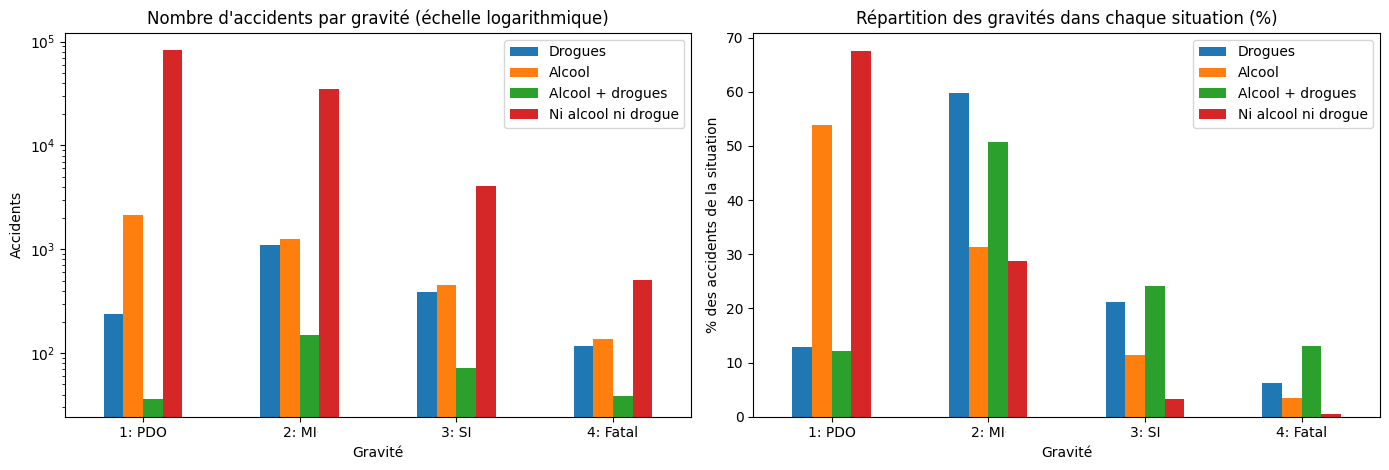

In [21]:
fr = {'On Drugs': 'Drogues', 'On Alcohol': 'Alcool', 'On Both': 'Alcool + drogues', 'On None': "Ni alcool ni drogue"}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

pd_df.rename(columns=fr).plot(kind='bar', ax=axes[0], rot=0, logy=True)
axes[0].set_title("Nombre d'accidents par gravité (échelle logarithmique)")
axes[0].set_xlabel("Gravité"); axes[0].set_ylabel("Accidents")

pd_df_per.rename(columns=fr).plot(kind='bar', ax=axes[1], rot=0)
axes[1].set_title("Répartition des gravités dans chaque situation (%)")
axes[1].set_xlabel("Gravité"); axes[1].set_ylabel("% des accidents de la situation")

plt.tight_layout()
plt.savefig('severe_per.png', dpi=130)
plt.show()

**Lecture.** Sans alcool ni drogue, deux accidents sur trois n'occasionnent que des dégâts matériels et seulement **0,42 %** sont mortels. Quand le conducteur est positif aux drogues, la part d'accidents mortels passe à **6,31 %** (et à **13,09 %** s'il y a drogue **et** alcool), et les dégâts matériels seuls ne représentent plus qu'environ 12 à 13 % des cas. Pour l'alcool seul, la part d'accidents mortels est de 3,42 %.

*À nuancer* : le dépistage n'est pas systématique (il est plus probable après un accident grave), donc une partie de l'écart peut venir de la façon dont les cas sont détectés, et pas seulement du comportement du conducteur.

## 3. Les mêmes requêtes avec RDD, DataFrame et Spark SQL

Une même question peut être traitée avec les trois API. On les compare ici sur deux requêtes, **en vérifiant que les trois donnent exactement le même résultat**.

Pour Spark SQL, on enregistre d'abord les DataFrames comme *vues temporaires*.

In [22]:
units_df.createOrReplaceTempView("units_table")
crash_df.createOrReplaceTempView("crash_table")
spark.sql("SELECT COUNT(*) AS nb_accidents FROM crash_table").show()

+------------+
|nb_accidents|
+------------+
|      127672|
+------------+



### Requête A : date, heure, victimes, sexe, âge et type de permis pour les accidents à Adelaide

Rappel : la « date » est *Année-Mois-JourDeLaSemaine*.

In [23]:
# ---------- RDD ----------
# On filtre d'abord (avant la jointure) pour réduire le volume mélangé entre partitions.
crash_kv = (crash_rdd.map(parse_csv)
            .filter(lambda f: f[ci['Suburb']] == 'ADELAIDE')
            .map(lambda f: (f[ci['REPORT_ID']],
                            ('-'.join([f[ci['Year']], f[ci['Month']], f[ci['Day']]]),
                             f[ci['Time']], int(f[ci['Total Cas']]), f[ci['Suburb']]))))
units_kv = (units_rdd.map(parse_csv)
            .map(lambda f: (f[ui['REPORT_ID']], (f[ui['Sex']], f[ui['Age']], f[ui['Licence Type']]))))

joined_rdd = units_kv.join(crash_kv)
A_rdd = joined_rdd.map(lambda kv: (kv[1][1][0], kv[1][1][1], kv[1][1][2],      # date, heure, victimes
                                   kv[1][0][0], kv[1][0][1], kv[1][0][2],      # sexe, âge, permis
                                   kv[1][1][3])).collect()                     # banlieue

# ---------- DataFrame ----------
joined_df = crash_df.join(units_df, on='REPORT_ID', how='inner')
A_df = (joined_df.filter(col('Suburb') == 'ADELAIDE')
        .withColumn('Date', F.concat_ws('-', 'Year', 'Month', 'Day'))
        .select('Date', 'Time', 'Total Cas', 'Sex', 'Age', 'Licence Type', 'Suburb'))

# ---------- Spark SQL ----------
A_sql = spark.sql('''
  SELECT concat_ws('-', Year, Month, Day) AS Date, Time, `Total Cas`, Sex, Age, `Licence Type`, Suburb
  FROM units_table u JOIN crash_table c ON u.REPORT_ID = c.REPORT_ID
  WHERE c.Suburb = 'ADELAIDE'
''')

norm = lambda rows: sorted(tuple('' if v is None else v for v in tuple(r)) for r in rows)
a_rdd, a_df, a_sql = norm(A_rdd), norm(A_df.collect()), norm(A_sql.collect())
print("Nombre de lignes : RDD =", len(a_rdd), "| DataFrame =", len(a_df), "| SQL =", len(a_sql))
print("RDD == DataFrame == SQL :", a_rdd == a_df == a_sql)
A_df.show(8, truncate=False)

Nombre de lignes : RDD = 11965 | DataFrame = 11965 | SQL = 11965
RDD == DataFrame == SQL : True
+---------------------+--------+---------+------+---+--------------+--------+
|Date                 |Time    |Total Cas|Sex   |Age|Licence Type  |Suburb  |
+---------------------+--------+---------+------+---+--------------+--------+
|2012-January-Monday  |08:45 am|0        |Male  |084|Full          |ADELAIDE|
|2012-January-Monday  |08:45 am|0        |Male  |040|Full          |ADELAIDE|
|2012-January-Friday  |05:45 pm|0        |Male  |047|Full          |ADELAIDE|
|2012-January-Friday  |05:45 pm|0        |Male  |XXX|NULL          |ADELAIDE|
|2012-January-Friday  |07:30 pm|1        |Female|018|Provisional 2 |ADELAIDE|
|2012-January-Friday  |07:30 pm|1        |Male  |020|Full          |ADELAIDE|
|2012-January-Saturday|08:00 am|0        |Female|024|Provisional 1 |ADELAIDE|
|2012-January-Saturday|08:00 am|0        |Male  |025|NULL          |ADELAIDE|
+---------------------+--------+---------+----

### Requête B : nombre total de victimes par banlieue quand le conducteur n'a pas de permis (`Unlicenced`)

In [24]:
# ---------- RDD ----------
unlic_units = (units_rdd.map(parse_csv)
               .filter(lambda f: f[ui['Licence Type']] == 'Unlicenced')
               .map(lambda f: (f[ui['REPORT_ID']], 1)))
crash_cas = crash_rdd.map(parse_csv).map(lambda f: (f[ci['REPORT_ID']], (f[ci['Suburb']], int(f[ci['Total Cas']]))))
B_rdd = (unlic_units.join(crash_cas)
         .map(lambda kv: (kv[1][1][0], kv[1][1][1]))          # (banlieue, victimes de l'accident)
         .reduceByKey(lambda a, b: a + b).collect())

# ---------- DataFrame ----------
B_df = (crash_df.join(units_df, on='REPORT_ID')
        .filter(col('Licence Type') == 'Unlicenced')
        .groupBy('Suburb').agg(F.sum('Total Cas').alias('Total casualty')))

# ---------- Spark SQL ----------
B_sql = spark.sql('''
  SELECT c.Suburb, SUM(c.`Total Cas`) AS `Total casualty`
  FROM units_table u JOIN crash_table c ON u.REPORT_ID = c.REPORT_ID
  WHERE u.`Licence Type` = 'Unlicenced'
  GROUP BY c.Suburb
''')

to_dict = lambda rows: {('' if r[0] is None else r[0]): int(r[1]) for r in rows}
b_rdd, b_df, b_sql = to_dict(B_rdd), to_dict(B_df.collect()), to_dict(B_sql.collect())
print("Banlieues :", len(b_rdd), "| RDD == DataFrame == SQL :", b_rdd == b_df == b_sql)
B_df.orderBy(col('Total casualty').desc()).show(10)

Banlieues : 752 | RDD == DataFrame == SQL : True
+--------------+--------------+
|        Suburb|Total casualty|
+--------------+--------------+
|      ADELAIDE|            43|
|     SALISBURY|            30|
|      PROSPECT|            27|
|    INGLE FARM|            22|
| MORPHETT VALE|            20|
|SALISBURY EAST|            20|
| MURRAY BRIDGE|            19|
|     DRY CREEK|            19|
|  MAWSON LAKES|            17|
|NORTH ADELAIDE|            17|
+--------------+--------------+
only showing top 10 rows


Les trois méthodes donnent exactement le même résultat. Le RDD demande d'écrire soi-même le découpage, la jointure et l'agrégation ; le DataFrame et SQL décrivent *ce qu'on veut* et laissent Spark choisir *comment* le faire. On retrouve aussi les valeurs du début de l'analyse (Adelaide = 43 victimes).

## 4. Deux problèmes de l'article, mesurés

**a) Le découpage naïf des lignes CSV fausse les requêtes RDD sur le fichier *crash*.**
Dans l'article, la requête RDD « victimes par banlieue » lit `Total Cas` après un `split(',')`. Sur les lignes dont `LGA Name` contient une virgule, la colonne lue est en réalité `Total Units` (la date et l'heure sont décalées de la même façon dans sa requête RDD n°1). Mesurons l'erreur sur le total des victimes :

In [25]:
def naive_total_cas(line):
    f = [v.replace('"', '') for v in line.split(',')]
    return int(f[6])                       # position de « Total Cas » SI aucune virgule parasite

naive_total = crash_rdd.map(naive_total_cas).sum()
true_total  = crash_df.agg(F.sum('Total Cas')).first()[0]
print(f"Total des victimes, découpage naïf      : {naive_total}")
print(f"Total des victimes, lecture correcte     : {true_total}")
print(f"Écart                                    : {naive_total - true_total:+d} ({(naive_total - true_total) / true_total:+.1%})")

Total des victimes, découpage naïf      : 63271
Total des victimes, lecture correcte     : 53255
Écart                                    : +10016 (+18.8%)


**b) Dans la 2ᵉ série de requêtes de l'article, les versions DataFrame et SQL comptent des lignes (`COUNT`), alors que la version RDD additionne les victimes (`SUM`)** ; elles ne répondent donc pas à la même question. De plus, d'après le code publié, elles écartent les permis « inconnus » au lieu de cibler les conducteurs sans permis, ce qui ne correspond pas à l'énoncé (« conducteur sans permis »). La section 3 ci-dessus utilise `SUM` et `Licence Type = 'Unlicenced'` dans les trois méthodes, ce qui permet d'obtenir des résultats identiques et cohérents avec la requête DF 4.

## 5. Pour aller plus loin : évolution dans le temps

Une extension simple (absente de l'article) : comment le nombre d'accidents évolue-t-il d'une année à l'autre, par gravité ?

+----+------+-----+-----+--------+
|Year|1: PDO|2: MI|3: SI|4: Fatal|
+----+------+-----+-----+--------+
|2012| 16729| 5377|  637|      86|
|2013| 10883| 5037|  666|      89|
|2014| 10467| 5005|  594|      96|
|2015| 10063| 4615|  657|      96|
|2016| 11562| 4562|  574|      77|
|2017|  8237| 4374|  533|      93|
|2018|  8646| 4393|  485|      75|
|2019|  8188| 3937|  729|     110|
+----+------+-----+-----+--------+



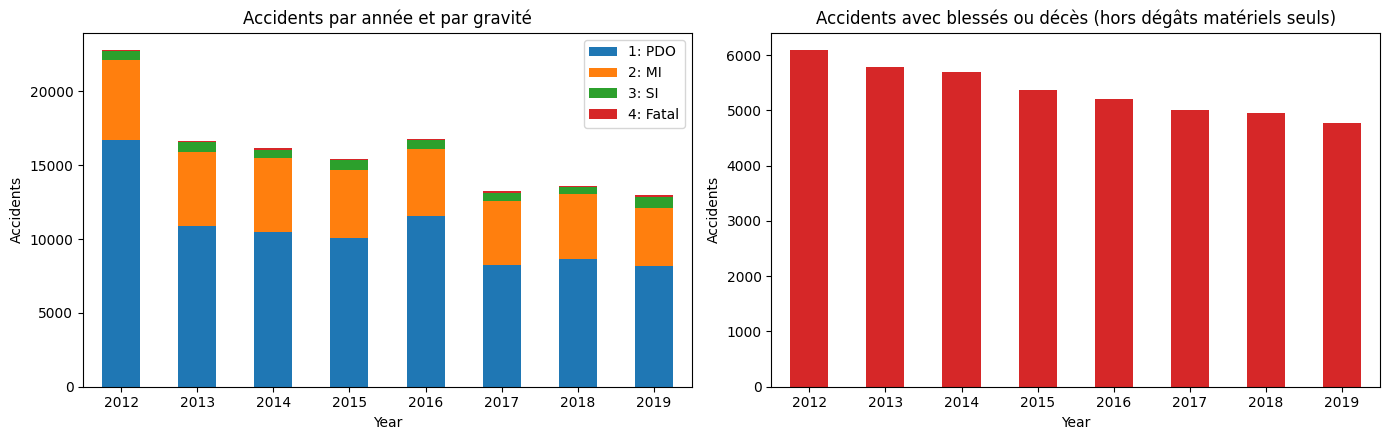

In [26]:
by_year = (crash_df.groupBy('Year').pivot('CSEF Severity', ['1: PDO', '2: MI', '3: SI', '4: Fatal'])
           .count().orderBy('Year'))
by_year.show()

pdf = by_year.toPandas().set_index('Year')
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
pdf.plot(kind='bar', stacked=True, ax=axes[0], rot=0)
axes[0].set_title("Accidents par année et par gravité"); axes[0].set_ylabel("Accidents")
pdf[['2: MI', '3: SI', '4: Fatal']].sum(axis=1).plot(kind='bar', ax=axes[1], rot=0, color='tab:red')
axes[1].set_title("Accidents avec blessés ou décès (hors dégâts matériels seuls)"); axes[1].set_ylabel("Accidents")
plt.tight_layout(); plt.show()

**Lecture.** Le nombre total d'accidents baisse nettement, mais il ne faut **pas** en conclure que les routes sont devenues plus sûres. Les métadonnées indiquent que le seuil de saisie des accidents « dégâts matériels seuls » (PDO) a changé le **1ᵉʳ janvier 2013** et le **1ᵉʳ janvier 2017** : les deux grosses chutes de la colonne `1: PDO` (16 729 → 10 883 en 2013, puis 11 562 → 8 237 en 2017) correspondent à ces dates. La légère remontée de 2016 s'explique vraisemblablement par le fait que tous les accidents avec dégâts matériels de décembre 2016 ont été traités (même source). Cette série n'est donc pas comparable d'une année à l'autre.

Les accidents avec blessés ou décès sont, eux, traités sur toute la période : ils sont plus fiables pour suivre une tendance. Ils passent de **6 100 en 2012 à 4 776 en 2019** (environ −22 %). Les décès restent stables à l'échelle de l'année (entre 75 et 110 par an, sans tendance nette, avec un maximum de 110 en 2019). Le bond des blessés graves en 2019 (729 contre 485 en 2018) mérite une vérification auprès du fournisseur de données avant toute interprétation.

## 6. Vérification : mes résultats = ceux de l'article

Chaque chiffre publié dans l'article qui peut être recalculé est comparé ci-dessous. Si une valeur diffère, la cellule s'arrête avec une erreur.

In [27]:
sev = {r['CSEF Severity']: r['Total accidents'] for r in severe_df.collect()}
fat = {r['Crash Type']: r['Total fatalities'] for r in fatal_by_type.collect()}
suburbs = {r['Suburb']: r['Total casualty'] for r in by_suburb_no_lic_df.collect()}
part = SA_partitioned_rdd.glom().map(len).collect()
def share(pdf_col, sev_label): return float(pd_df_per.loc[sev_label, pdf_col])

checks = {
    "Lignes crash_rdd = 127 672":                 crash_rdd.count() == 127672,
    "Lignes units_rdd = 272 591":                 units_rdd.count() == 272591,
    "Partitions SA / autres = 218 366 / 54 225":  part == [218366, 54225],
    "Âge moyen hommes = 40,8":                    avg_groupby['Male'] == 40.8,
    "Âge moyen femmes = 40,08":                   avg_groupby['Female'] == 40.08,
    "Gravité : 722 / 37 300 / 84 775 / 4 875":    (sev['4: Fatal'], sev['2: MI'], sev['1: PDO'], sev['3: SI']) == (722, 37300, 84775, 4875),
    "Décès, obstacle fixe = 245":                 fat['Hit Fixed Object'] == 245.0,
    "Décès, collision frontale = 136":            fat['Head On'] == 136.0,
    "Décès, piéton = 109":                        fat['Hit Pedestrian'] == 109.0,
    "Sans permis : Adelaide 43, Salisbury 30":    (suburbs['ADELAIDE'], suburbs['SALISBURY']) == (43, 30),
    "Drogue : % mortels = 6,31":                  share('On Drugs', '4: Fatal') == 6.31,
    "Alcool : % mortels = 3,42":                  share('On Alcohol', '4: Fatal') == 3.42,
    "Alcool+drogue : % mortels = 13,09":          share('On Both', '4: Fatal') == 13.09,
    "Aucun : % mortels = 0,42":                   share('On None', '4: Fatal') == 0.42,
    "RDD = DataFrame = SQL (requête A)":          a_rdd == a_df == a_sql,
    "RDD = DataFrame = SQL (requête B)":          b_rdd == b_df == b_sql,
}
for name, ok in checks.items():
    print(("OK   " if ok else "ECHEC"), name)
assert all(checks.values()), "Au moins une vérification a échoué"
print("\nToutes les vérifications passent.")

OK    Lignes crash_rdd = 127 672
OK    Lignes units_rdd = 272 591
OK    Partitions SA / autres = 218 366 / 54 225
OK    Âge moyen hommes = 40,8
OK    Âge moyen femmes = 40,08
OK    Gravité : 722 / 37 300 / 84 775 / 4 875
OK    Décès, obstacle fixe = 245
OK    Décès, collision frontale = 136
OK    Décès, piéton = 109
OK    Sans permis : Adelaide 43, Salisbury 30
OK    Drogue : % mortels = 6,31
OK    Alcool : % mortels = 3,42
OK    Alcool+drogue : % mortels = 13,09
OK    Aucun : % mortels = 0,42
OK    RDD = DataFrame = SQL (requête A)
OK    RDD = DataFrame = SQL (requête B)

Toutes les vérifications passent.


## 7. Conclusion

- **Données** : 127 672 accidents et 272 591 véhicules/unités entre 2012 et 2019, traités avec Spark en local sur tous les cœurs disponibles.
- **Trois API, mêmes résultats** : RDD (contrôle total mais code long et fragile), DataFrame et Spark SQL (plus concis, optimisés par Spark). Les résultats sont identiques lorsque les requêtes posent la même question.
- **Constats** : les accidents contre un obstacle fixe sont les plus meurtriers ; l'âge moyen des conducteurs impliqués est d'environ 40 ans quel que soit le sexe ; la part d'accidents mortels est environ **15 fois plus élevée** quand le conducteur est positif aux drogues (6,31 %) que lorsqu'il ne l'est ni à l'alcool ni aux drogues (0,42 %).
- **Limites** : dépistage non systématique (biais de détection), valeurs par défaut dans les données (véhicules de 1900, `XXX`, `Unknown`), et changements du seuil de saisie des accidents avec dégâts matériels seuls (2013 et 2017, d'après les métadonnées), qui rendent le total annuel d'accidents non comparable ; seuls les accidents avec blessés ou décès permettent de suivre une tendance.
- **Bonnes pratiques retenues** : lire le CSV avec un vrai parseur, préférer `reduceByKey` à `groupByKey`, éviter les UDF quand une fonction native existe, agréger dans Spark avant `toPandas()`, et mettre en cache les DataFrames réutilisés.

In [28]:
spark.stop()